# Aviation Accidents Analysis

You are part of a consulting firm that is tasked to do an analysis of commercial and passenger jet airline safety. The client (an airline/airplane insurer) is interested in knowing what types of aircraft (makes/models) exhibit low rates of total destruction and low likelihood of fatal or serious passenger injuries in the event of an accident. They are also interested in any general variables/conditions that might be at play. Your analysis will be based off of aviation accident data accumulated from the years 1948-2023. 

Our client is only interested in airplane makes/models that are professional builds and could potentially still be active. Assume a max lifetime of 40 years for a make/model retirement and make sure to filter your data accordingly (i.e. from 1983 onwards). They would also like separate recommendations for small aircraft vs. larger passenger models. **In addition, make sure that claims that you make are statistically robust and that you have enough samples when making comparisons between groups.**


In this summative assessment you will demonstrate your ability to:
- Use Pandas to load, inspect, and clean the dataset appropriately. 
- Transform relevant columns to create measures that address the problem at hand.
- **conduct EDA: visualization and statistical measures to understand the structure of the data**
- **recommend a set of manufacturers to consider as well as specific airplanes conforming to the client's request**
- **discuss the relationship between serious injuries/airplane damage incurred and at least *two* factors at play in the incident. You must provide supporting evidence (visuals, summary statistics, tables) for each claim you make.**

In [15]:
# loading relevant packages
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

## Exploratory Data Analysis  
- Load in the cleaned data

In [16]:
file_path="./data/cleaned_aviation_data.csv"

#load data 
aviation_df=pd.read_csv(file_path)

aviation_df

/var/folders/_r/g1b4b9xn2nn0xtb2011g11v80000gp/T/ipykernel_95800/1393040385.py:4: DtypeWarning: Columns (0: Event.Id, 1: Broad.phase.of.flight) have mixed types. Specify dtype option on import or set low_memory=False.
  aviation_df=pd.read_csv(file_path)


,Event.Id,Investigation.Type,Accident.Number,Event.Date,Location,Country,Airport.Code,Airport.Name,Injury.Severity,Aircraft.damage,...,Total.Minor.Injuries,Total.Uninjured,Weather.Condition,Broad.phase.of.flight,Report.Status,Publication.Date,Total.People,pct_fatal_and_serious,is_destroyed,Plane.Type
0,20001214X42095,Accident,SEA83LA036,1983-01-01,"NEWPORT, OR",United States,ONP,NEWPORT MUNICIPAL,Non-Fatal,Substantial,...,1.0,3.0,VMC,Approach,Probable Cause,NaN,4.0,0.0,0.0,Cessna 182P
1,20001214X42067,Accident,MKC83LA056,1983-01-01,"WOODBINE, IA",United States,3YR,MUNICIPAL,Non-Fatal,Substantial,...,0.0,2.0,VMC,Landing,Probable Cause,NaN,2.0,0.0,0.0,Cessna 182RG
2,20001214X42063,Accident,MKC83LA050,1983-01-01,"MARYVILLE, MO",United States,78Y,RANKIN,Non-Fatal,Substantial,...,0.0,1.0,VMC,Takeoff,Probable Cause,NaN,1.0,0.0,0.0,Cessna 182P
3,20001214X42018,Accident,LAX83FUG11,1983-01-01,"UPLAND, CA",United States,CCB,CABLE,Non-Fatal,Substantial,...,2.0,0.0,VMC,Approach,Probable Cause,NaN,2.0,0.0,0.0,Piper PA-28R-200
4,20001214X41951,Accident,CHI83LA074,1983-01-01,"SPRINGBROOK, WI",United States,NaN,SPRINGBROOK,Non-Fatal,Substantial,...,0.0,2.0,VMC,Landing,Probable Cause,NaN,2.0,0.0,0.0,Cessna 140
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
66846,20221227106491,Accident,ERA23LA093,2022-12-26,"Annapolis, MD",United States,NaN,NaN,Minor,NaN,...,0.0,0.0,NaN,NaN,NaN,29-12-2022,1.0,100.0,NaN,Piper PA-28-151
66847,20221227106494,Accident,ERA23LA095,2022-12-26,"Hampton, NH",United States,NaN,NaN,NaN,NaN,...,0.0,0.0,NaN,NaN,NaN,NaN,0.0,NaN,NaN,Bellanca 7ECA
66848,20221227106497,Accident,WPR23LA075,2022-12-26,"Payson, AZ",United States,PAN,PAYSON,Non-Fatal,Substantial,...,0.0,1.0,VMC,NaN,NaN,27-12-2022,1.0,0.0,0.0,American Champion Aircraft 8GCBC
66849,20221227106498,Accident,WPR23LA076,2022-12-26,"Morgan, UT",United States,NaN,NaN,NaN,NaN,...,0.0,0.0,NaN,NaN,NaN,NaN,0.0,NaN,NaN,Cessna 210N


## Explore safety metrics across models/makes
- Remember that the client is interested in separate recommendations for smaller airplanes and larger airplanes. Choose a passenger threshold of 20 and separate the plane types. 

In [17]:
# create zize column to signify if the aircraft is large or small
def create_size_column(row):
    if pd.isna(row["Total.People"]):
      return np.nan
    elif row["Total.People"] > 20:
        return "Large"
    else:
        return "Small"
    
aviation_df["Size"] =aviation_df.apply(create_size_column,axis=1)

aviation_df["Size"].isna().sum()

 

np.int64(11083)

In [22]:
aviation_df.columns

Index(['Event.Id', 'Investigation.Type', 'Accident.Number', 'Event.Date',
       'Location', 'Country', 'Airport.Code', 'Airport.Name',
       'Injury.Severity', 'Aircraft.damage', 'Registration.Number', 'Make',
       'Model', 'Amateur.Built', 'Number.of.Engines', 'Engine.Type',
       'Purpose.of.flight', 'Total.Fatal.Injuries', 'Total.Serious.Injuries',
       'Total.Minor.Injuries', 'Total.Uninjured', 'Weather.Condition',
       'Broad.phase.of.flight', 'Report.Status', 'Publication.Date',
       'Total.People', 'pct_fatal_and_serious', 'is_destroyed', 'Plane.Type',
       'Size'],
      dtype='str')

#### Analyzing Makes

Explore the human injury risk profile for small and larger Makes:
- choose the 15 makes for each group possessing the lowest mean fatal/seriously injured fraction
- plot the mean fatal/seriously injured fraction for each of these subgroups side-by-side

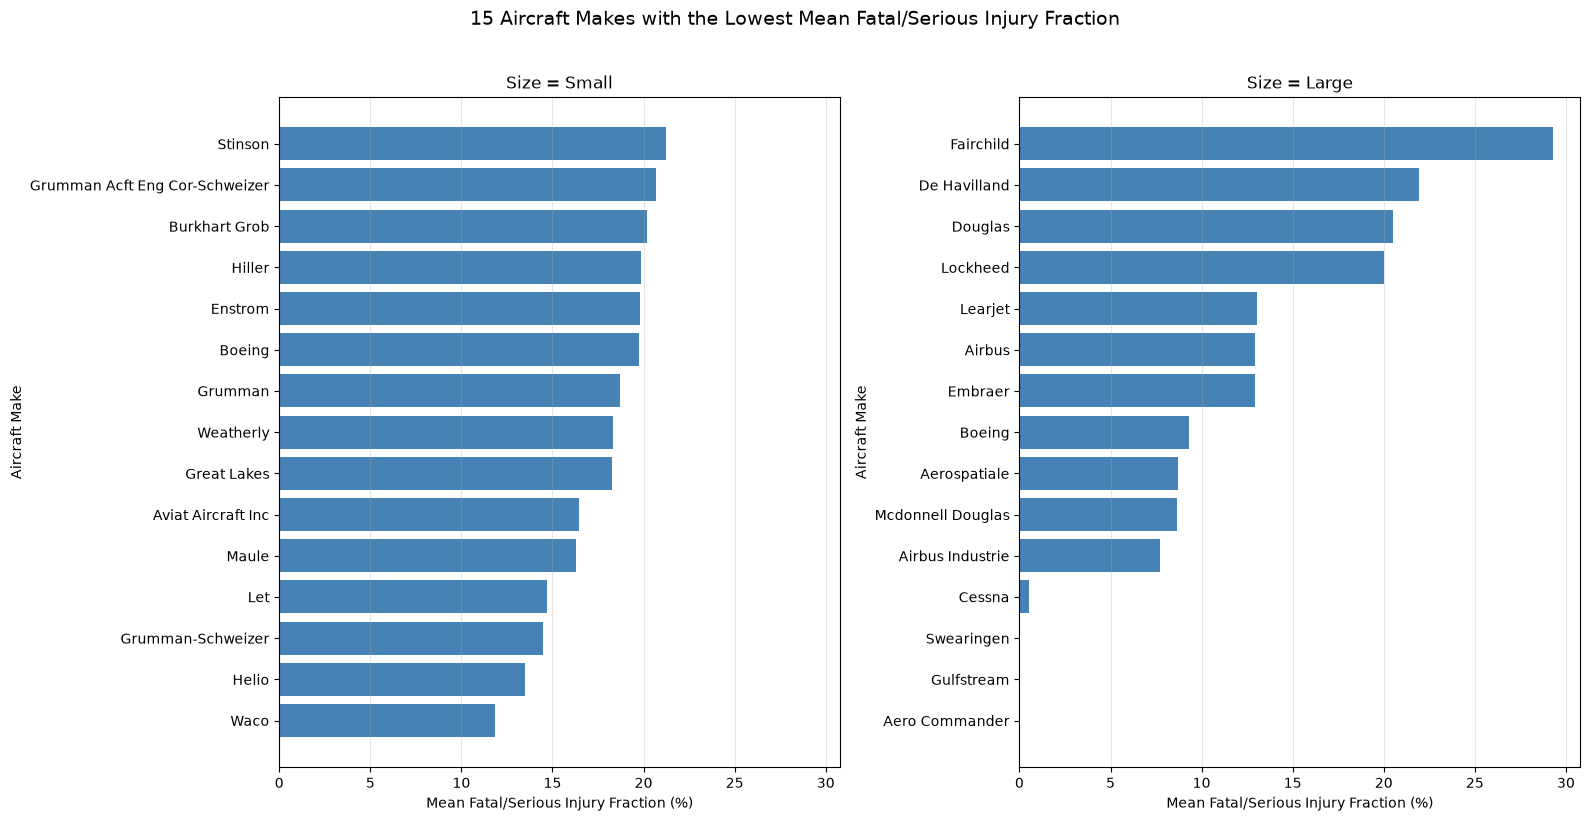

In [44]:
# 1. Properly get the true 15 lowest per size group independently
lowest_15 = (
    aviation_df.groupby(["Size", "Make"])["pct_fatal_and_serious"]
    .mean()
    .groupby(level="Size", group_keys=False)
    .nsmallest(15)
    .reset_index()
)

# 2. Plot Small and Large side-by-side cleanly
fig, axes = plt.subplots(1, 2, figsize=(16, 8), sharex=True)

for ax, size in zip(axes, ["Small", "Large"]):
    # Isolate and sort the exact 15 for this size in ascending order
    subset = (
        lowest_15[lowest_15["Size"] == size]
        .sort_values("pct_fatal_and_serious", ascending=True)
        .reset_index(drop=True)
    )

    # Plot horizontal bars for this specific size subset
    ax.barh(subset["Make"], subset["pct_fatal_and_serious"], color="steelblue")

    ax.set_title(f"Size = {size}")
    ax.set_xlabel("Mean Fatal/Serious Injury Fraction (%)")
    ax.set_ylabel("Aircraft Make")
    ax.grid(axis="x", alpha=0.3)

plt.suptitle(
    "15 Aircraft Makes with the Lowest Mean Fatal/Serious Injury Fraction",
    fontsize=14,
    y=1.02,
)
plt.tight_layout()
plt.show()

**Distribution of injury rates: small makes**

Use a violinplot to look at the distribution of the fraction of passengers serious/fatally injured for small airplane makes. Just display makes with the ten lowest mean serious/fatal injury rates.

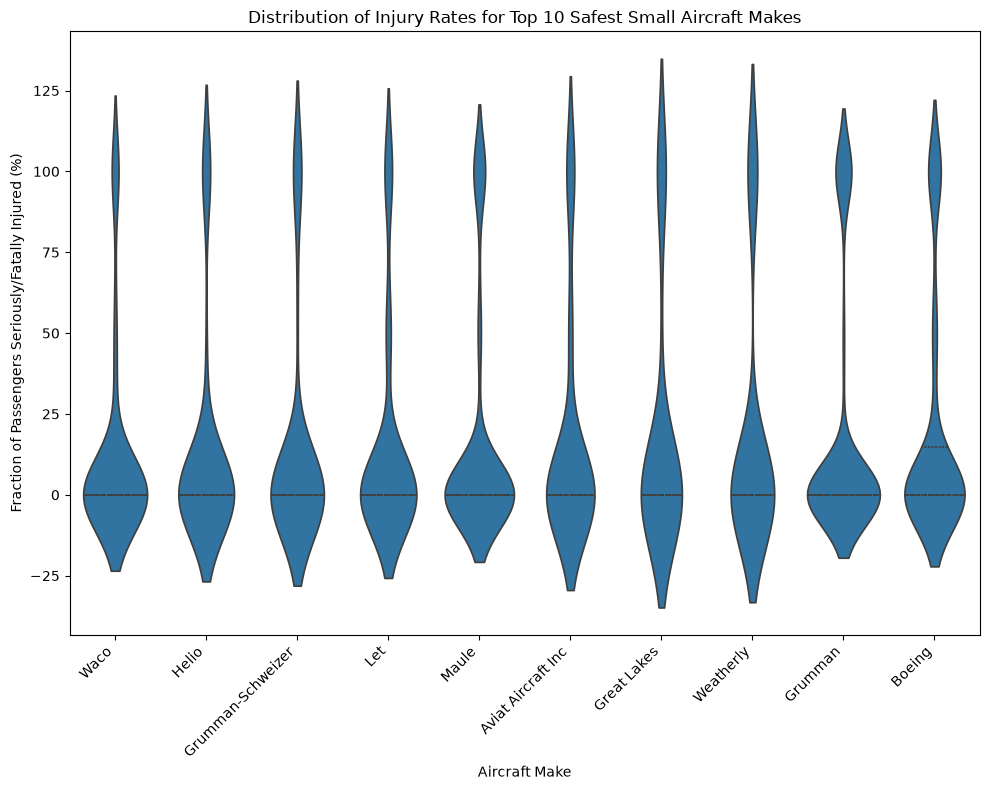

In [60]:

small_lowest_10 =(aviation_df[aviation_df["Size"]=="Small"].groupby("Make")["pct_fatal_and_serious"].mean().nsmallest(10))
type(small_lowest_10)
small_lowest_10
# 1. Get the names of the 10 small makes with the lowest mean injury rates
top_10_makes = small_lowest_10.index
# 2. Filter the main dataframe to get ALL raw accident rows for these 10 makes
violin_df = aviation_df[
    (aviation_df["Size"] == "Small") & 
    (aviation_df["Make"].isin(top_10_makes))
]

fig,ax=plt.subplots(figsize=(10,8))
sns.violinplot(data=violin_df,
    x="Make",
    y="pct_fatal_and_serious",
    order=top_10_makes,  # Keeps them sorted by lowest mean
    ax=ax,
    inner="quart")
ax.set_ylabel("Fraction of Passengers Seriously/Fatally Injured (%)")
ax.set_title("Distribution of Injury Rates for Top 10 Safest Small Aircraft Makes")
ax.set_xlabel("Aircraft Make")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()



**Distribution of injury rates: large makes**

Use a stripplot to look at the distribution of the fraction of passengers serious/fatally injured for large airplane makes. Just display makes with the ten lowest mean serious/fatal injury rates.

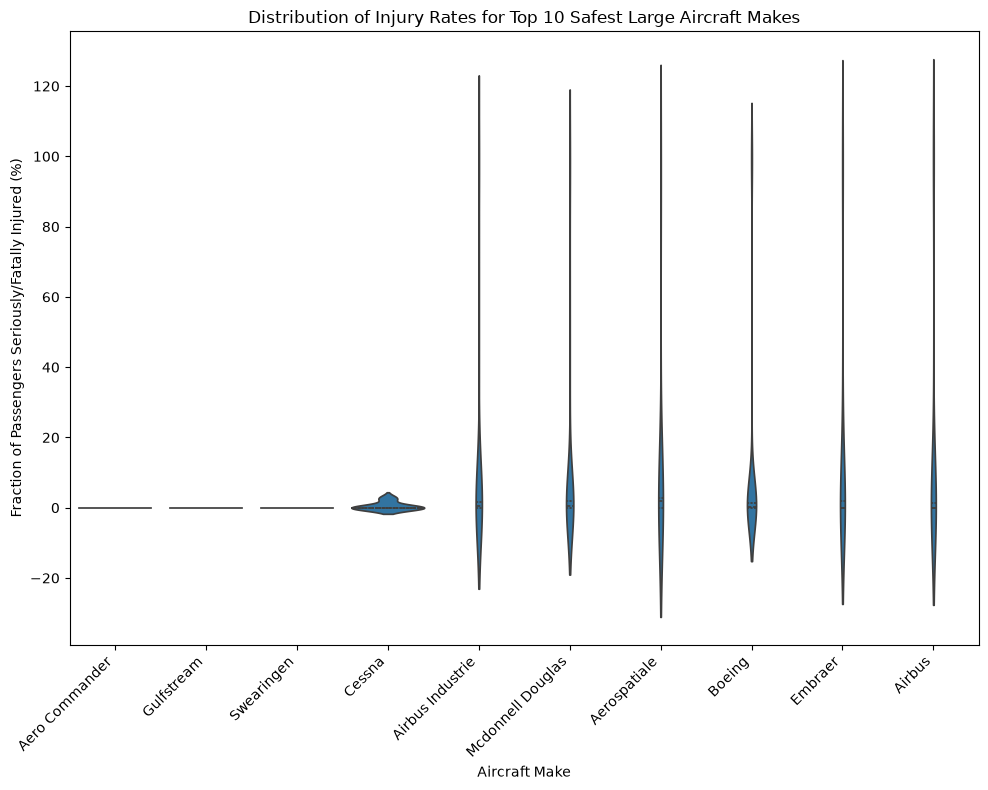

In [61]:
largest_lowest_10 =(aviation_df[aviation_df["Size"]=="Large"].groupby("Make")["pct_fatal_and_serious"].mean().nsmallest(10))


# 1. Get the names of the 10 small makes with the lowest mean injury rates
top_10_makes = largest_lowest_10.index
# 2. Filter the main dataframe to get ALL raw accident rows for these 10 makes
violin_df = aviation_df[
    (aviation_df["Size"] == "Large") & 
    (aviation_df["Make"].isin(top_10_makes))
]

fig,ax=plt.subplots(figsize=(10,8))
sns.violinplot(data=violin_df,
    x="Make",
    y="pct_fatal_and_serious",
    order=top_10_makes,  # Keeps them sorted by lowest mean
    ax=ax,
    inner="quart")
ax.set_ylabel("Fraction of Passengers Seriously/Fatally Injured (%)")
ax.set_title("Distribution of Injury Rates for Top 10 Safest Large Aircraft Makes")
ax.set_xlabel("Aircraft Make")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

**Evaluate the rate of aircraft destruction for both small and large aircraft by Make.** 

Sort your results and keep the lowest 15.

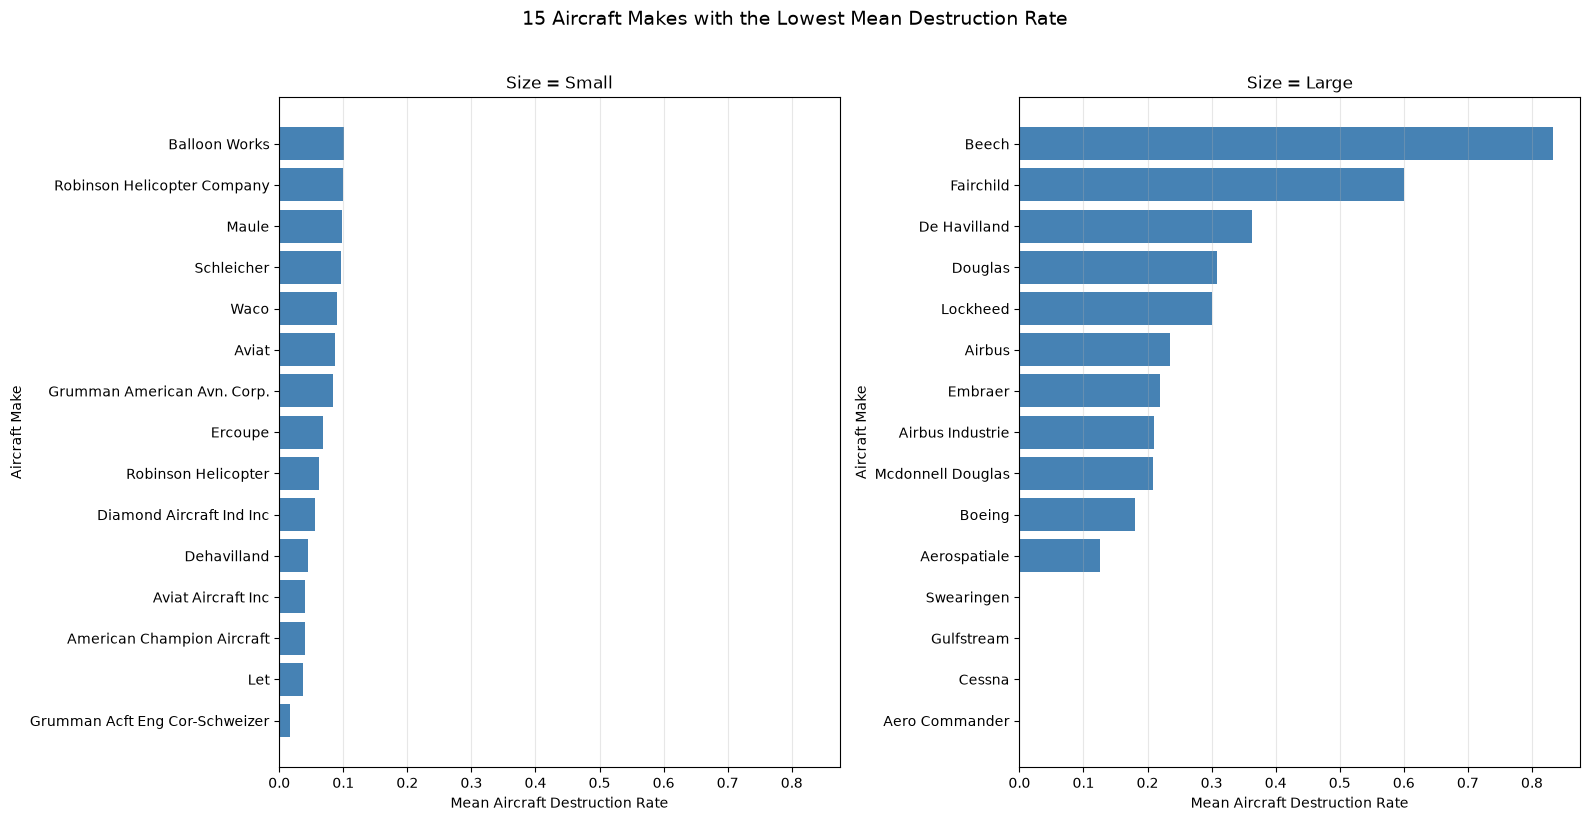

In [69]:
# 1. Calculate destruction rate and reset index so Size and Make are columns
lowest_15 = (
    aviation_df.groupby(["Size", "Make"])["is_destroyed"]
    .mean()
    .groupby(level="Size", group_keys=False)
    .nsmallest(15)
    .reset_index()
)

# 2. Plot Small and Large side-by-side cleanly
fig, axes = plt.subplots(1, 2, figsize=(16, 8), sharex=True)

for ax, size in zip(axes, ["Small", "Large"]):
    # Isolate and sort the exact 15 for this size in ascending order
    subset = (
        lowest_15[lowest_15["Size"] == size]
        .sort_values("is_destroyed", ascending=True)
        .reset_index(drop=True)
    )

    # Plot horizontal bars using the destruction rate column
    ax.barh(subset["Make"], subset["is_destroyed"], color="steelblue")

    ax.set_title(f"Size = {size}")
    ax.set_xlabel("Mean Aircraft Destruction Rate")
    ax.set_ylabel("Aircraft Make")
    ax.grid(axis="x", alpha=0.3)

plt.suptitle(
    "15 Aircraft Makes with the Lowest Mean Destruction Rate",
    fontsize=14,
    y=1.02,
)
plt.tight_layout()
plt.show()


#### Provide a short discussion on your findings for your summary statistics and plots:
- Make any recommendations for Makes here based off of the destroyed fraction and fraction fatally/seriously injured
- Comment on the calculated statistics and any corresponding distributions you have visualized.

## Summary Discussion of Findings

### 1. Injury Risk

- **Small aircraft:** Waco, Helio, and Grumman-Schweizer had low mean fatal/serious injury fractions.
- **Large aircraft:** Aero Commander, Gulfstream, Swearingen, and Cessna showed low mean injury fractions.


### 2. Aircraft Destruction Rates

- **Small aircraft:** Balloon Works and Robinson Helicopter Company showed low destruction rates.
- **Large aircraft:** Aero Commander, Cessna, and Gulfstream showed low destruction rates.


### 3. Injury Rate Distributions

The violin plots show that injury rates vary across accidents. Although many observations have rates near 0%, some reach 100%, meaning severe outcomes remain possible. Low average injury rates do not guarantee safety.

### Recommendation
- **Large Aircraft** consider Aero Commander and Gulfstream which showed low injury fractions and destruction rates

### Analyze plane types
- plot the mean fatal/seriously injured fraction for both small and larger planes 
- also provide a distributional plot of your choice for the fatal/seriously injured fraction by airplane type (stripplot, violin, etc)  
- filter ensuring that you have at least ten individual examples in each model/make to average over

**Larger planes**

,events,mean_frac
Plane.Type,,
Boeing 757,12,0.286547
Boeing 757-232,11,0.412014
Mcdonnell Douglas DC-10-10,10,5.933859
Boeing 777,13,7.466506
Boeing 767,19,7.710189
Boeing 737 7H4,12,7.947427
Boeing 727-200,13,8.805483
Boeing 737-300,15,10.671408
Boeing 737,83,16.172367


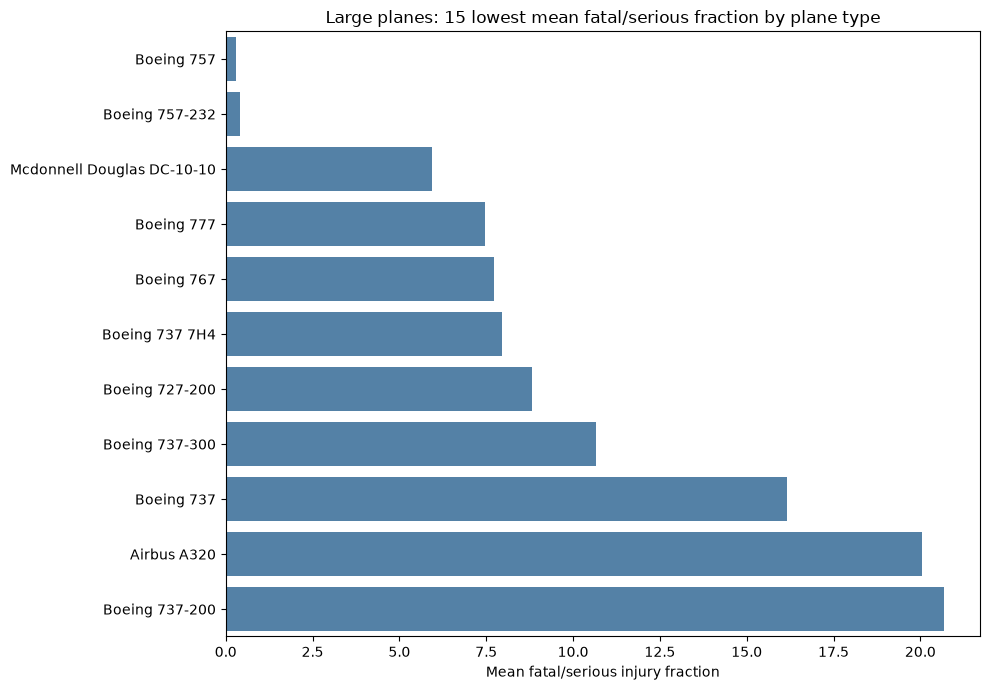

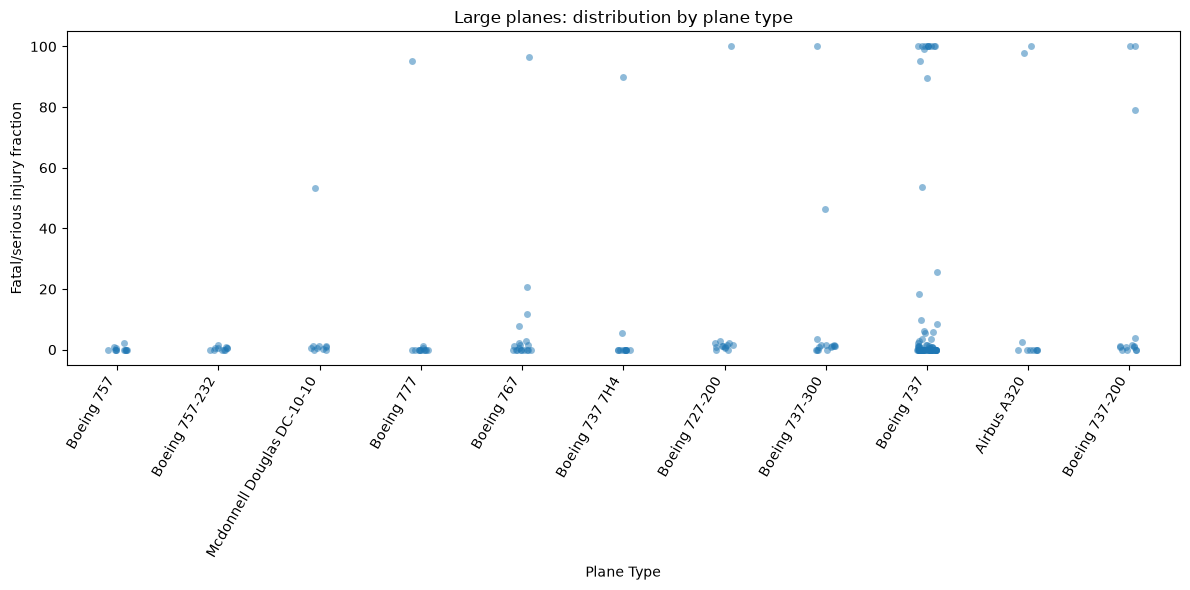

In [86]:
# 1. Define the minimum sample size threshold to ensure statistical significance
MIN_TYPE_EVENTS = 10

# 2. Split the dataset into Large and Small aircraft subsets
# (Replace 'aviation_df' and 'Size' with your actual dataframe/column names if they differ)
large = aviation_df[aviation_df["Size"] == "Large"]
small = aviation_df[aviation_df["Size"] == "Small"]


# 3. Define the reusable function to calculate stats and apply the sample filter
def type_stats(group_df, n=None):
  stats = group_df.groupby("Plane.Type").agg(
      events=("Plane.Type", "size"),
      mean_frac=("pct_fatal_and_serious", "mean"),
  )
  stats = stats[stats["events"] >= MIN_TYPE_EVENTS].sort_values("mean_frac")
  return stats if n is None else stats.head(n)


# ==========================================
# PART A: LARGE PLANES ANALYSIS & PLOTTING
# ==========================================
large_types = type_stats(large, n=15)
display(large_types)

# Large: Mean fraction bar plot
plt.figure(figsize=(10, 7))
sns.barplot(x=large_types["mean_frac"], y=large_types.index, color="steelblue")
plt.xlabel("Mean fatal/serious injury fraction")
plt.ylabel("")
plt.title("Large planes: 15 lowest mean fatal/serious fraction by plane type")
plt.tight_layout()
plt.show()

# Large: Distributional strip plot
plt.figure(figsize=(12, 6))
sns.stripplot(
    data=large[large["Plane.Type"].isin(large_types.index)],
    x="Plane.Type",
    y="pct_fatal_and_serious",
    order=large_types.index,
    jitter=True,
    alpha=0.5,
)
plt.xticks(rotation=60, ha="right")
plt.ylabel("Fatal/serious injury fraction")
plt.xlabel("Plane Type")
plt.title("Large planes: distribution by plane type")
plt.tight_layout()
plt.show()

**Smaller planes**
- for smaller planes, limit your plotted results to the makes with the 10 lowest mean serious/fatal injury fractions

,events,mean_frac
Plane.Type,,
Diamond Aircraft Ind Inc DA 20 C1,11,0.000000
Grumman G164B,14,0.000000
Cessna 180C,11,0.000000
Piper PA-18A 150,11,0.000000
Burkhart Grob G103,13,3.846154
Air Tractor AT 602,12,4.166667
Piper PA-18-180,12,4.166667
Weatherly 201B,23,4.347826
Cessna C172,11,4.545455


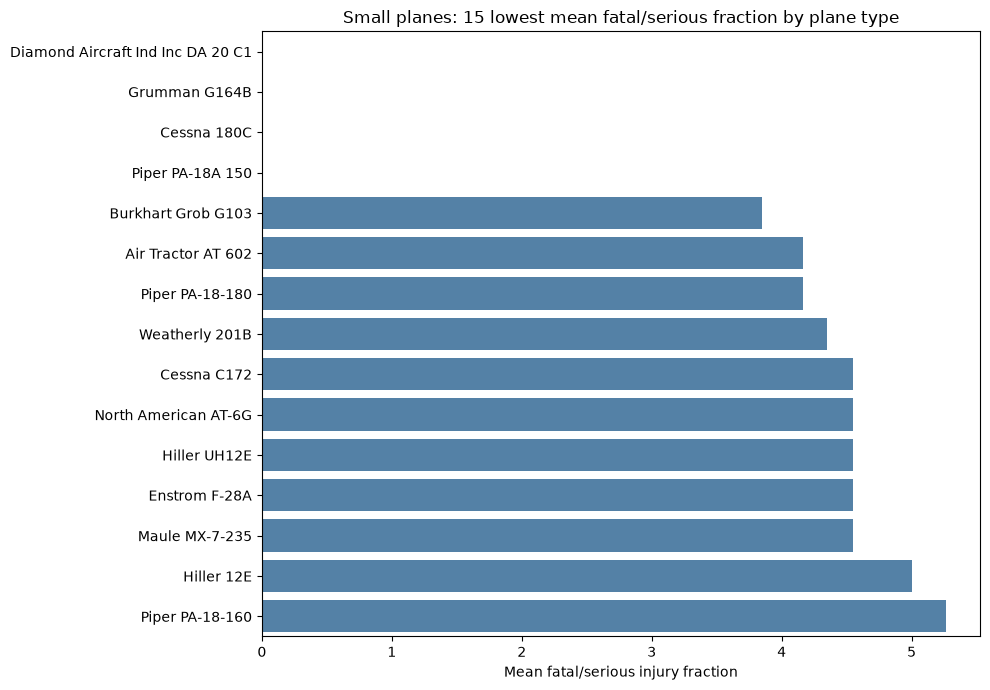

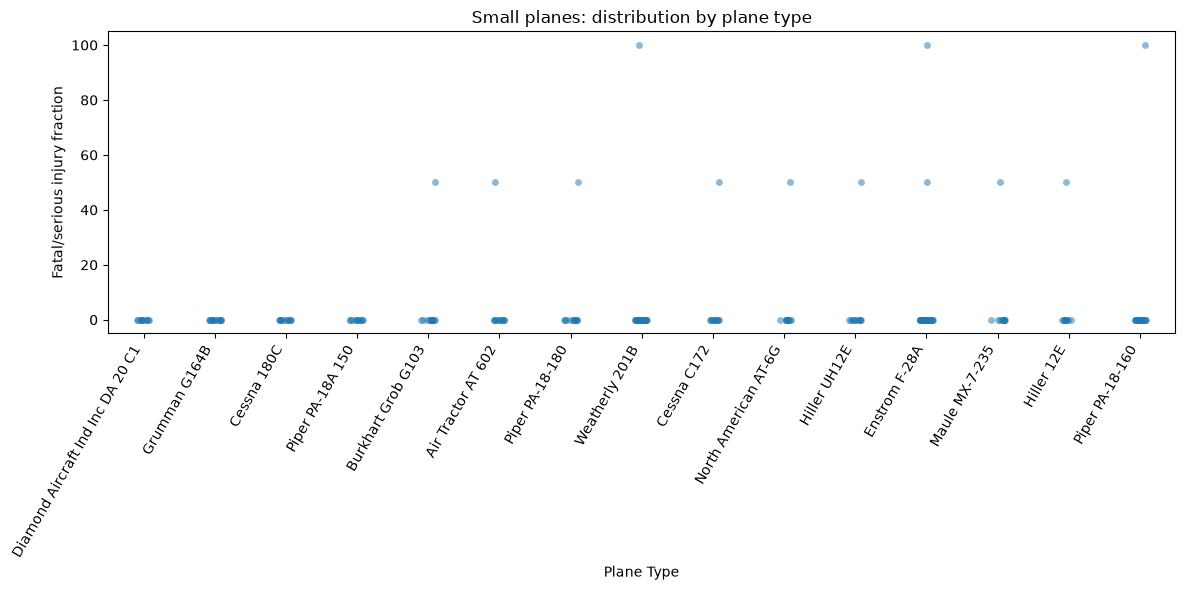

In [89]:
small_types = type_stats(small, n=15)
display(small_types)

# Small: Mean fraction bar plot
plt.figure(figsize=(10, 7))
sns.barplot(x=small_types["mean_frac"], y=small_types.index, color="steelblue")
plt.xlabel("Mean fatal/serious injury fraction")
plt.ylabel("")
plt.title("Small planes: 15 lowest mean fatal/serious fraction by plane type")
plt.tight_layout()
plt.show()

# Small: Distributional strip plot
plt.figure(figsize=(12, 6))
sns.stripplot(
    data=small[small["Plane.Type"].isin(small_types.index)],
    x="Plane.Type",
    y="pct_fatal_and_serious",
    order=small_types.index,
    jitter=True,
    alpha=0.5,
)
plt.xticks(rotation=60, ha="right")
plt.ylabel("Fatal/serious injury fraction")
plt.xlabel("Plane Type")
plt.title("Small planes: distribution by plane type")
plt.tight_layout()
plt.show()


### Discussion of Specific Airplane Types
- Discuss what you have found above regarding passenger fraction seriously/ both small and large airplane models.

## Discussion of Specific Airplane Types

The analysis considered airplane types with at least 10 recorded events.

### 1. Large Airplanes

- **Low injury rates:** Boeing 757, McDonnell Douglas DC-10-10, Boeing 737 variants, and Airbus A320 showed low average serious and fatal injury fractions.
- **Variation in outcomes:** Most recorded events had injury rates close to 0%, but some reached 100%. This shows that severe outcomes can still occur.

### 2. Small Airplanes

- **Low injury rates:** Diamond DA20 C1, Grumman G164B, Cessna 180C, and several Piper models showed low average injury fractions.
- **Variation in outcomes:** Most events had no serious or fatal injuries, but a few had high injury rates.



### Exploring Other Variables
- Investigate how other variables effect aircraft damage and injury. You must choose **two** factors out of the following but are free to analyze more:

- Weather Condition
- Engine Type
- Number of Engines
- Phase of Flight
- Purpose of Flight

For each factor provide a discussion explaining your analysis with appropriate visualization / data summaries and interpreting your findings.

,events,mean_fatal_serious,destroyed_frac
Weather.Condition,,,
Imc,5024,66.531882,0.597648
Unknown,3286,58.336667,0.414508
Vmc,58541,23.038489,0.173937


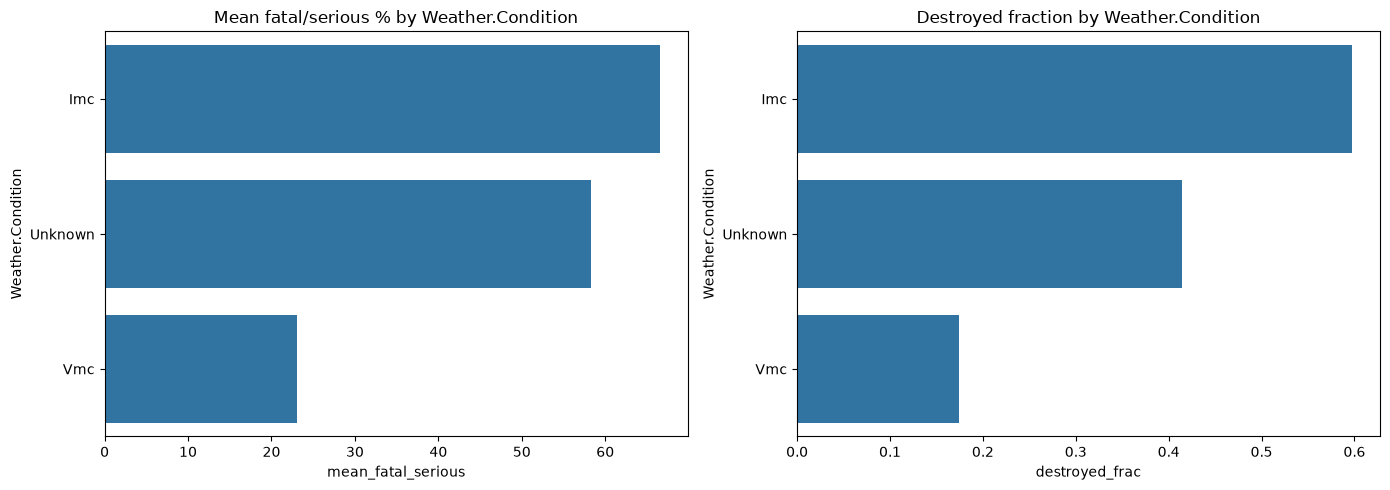

,events,mean_fatal_serious,destroyed_frac
Broad.phase.of.flight,,,
Maneuvering,6224,46.285428,0.424194
Climb,1497,43.153915,0.434040
Other,74,39.877810,0.309859
Cruise,8064,35.379645,0.347311
Unknown,18968,34.623605,0.168303
Approach,5014,34.075126,0.293528
Descent,1464,33.039752,0.323636
Go-Around,1170,29.438763,0.290847
Takeoff,9466,22.762709,0.223422


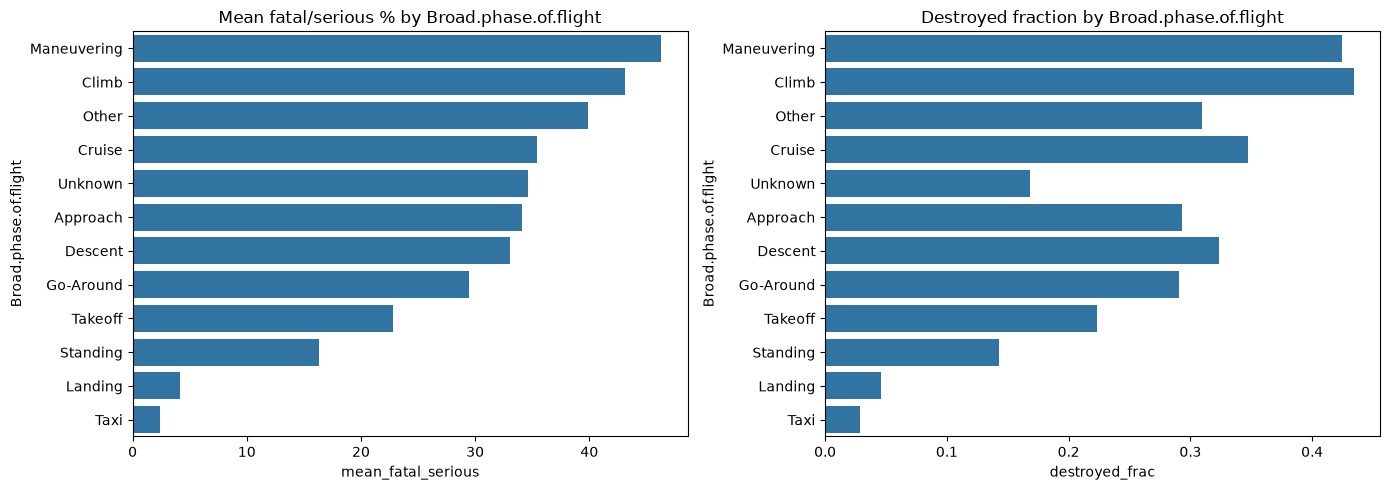

In [78]:
for col in ["Weather.Condition", "Broad.phase.of.flight"]:
    # Clean: standardize missing/unknown labels
    aviation_df[col] = aviation_df[col].str.strip().str.title().replace({"Unk": "Unknown"}).fillna("Unknown")

    summary = aviation_df.groupby(col).agg(
        events=(col, "size"),
        mean_fatal_serious=("pct_fatal_and_serious", "mean"),
        destroyed_frac=("is_destroyed", "mean"),
    ).sort_values("mean_fatal_serious", ascending=False)
    display(summary)

    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    sns.barplot(x=summary["mean_fatal_serious"], y=summary.index, ax=axes[0])
    axes[0].set_title(f"Mean fatal/serious % by {col}")
    sns.barplot(x=summary["destroyed_frac"], y=summary.index, ax=axes[1])
    axes[1].set_title(f"Destroyed fraction by {col}")
    plt.tight_layout()
    plt.show()

##### Weather Condition

Accidents in instrument meteorological conditions (IMC) were more severe than those in visual conditions (VMC). IMC had higher fatal/serious injury fractions (63 %vs. 25%) and destruction rates (0.58 vs. 0.18). Unknown weather fell between the two.

#### Phase of Flight

Maneuvering and climb had the highest injury fractions and destruction rates, while landing and taxi had the lowest. However, many events had an unknown flight phase, limiting the conclusions.

In [82]:
aviation_df.columns

Index(['Event.Id', 'Investigation.Type', 'Accident.Number', 'Event.Date',
       'Location', 'Country', 'Airport.Code', 'Airport.Name',
       'Injury.Severity', 'Aircraft.damage', 'Registration.Number', 'Make',
       'Model', 'Amateur.Built', 'Number.of.Engines', 'Engine.Type',
       'Purpose.of.flight', 'Total.Fatal.Injuries', 'Total.Serious.Injuries',
       'Total.Minor.Injuries', 'Total.Uninjured', 'Weather.Condition',
       'Broad.phase.of.flight', 'Report.Status', 'Publication.Date',
       'Total.People', 'pct_fatal_and_serious', 'is_destroyed', 'Plane.Type',
       'Size'],
      dtype='str')